# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

In [2]:
import h5py
f = h5py.File('/home/roman/Documents/code/SmartNets_Seminars/hackathon/0066/0066_000_fov.h5', 'r')

In [3]:
group = f['fields']
group.keys()

<KeysViewHDF5 ['version', 'date', 'detected', 'x', 'y', 'heading_x', 'heading_y', 'left_eye_x', 'left_eye_y', 'right_eye_x', 'right_eye_y', 'ang_area_left_eye', 'ang_area_right_eye', 'ang_com_left_eye', 'ang_com_right_eye', 'fov_distance', 'fov_identity', 'sobj_x', 'sobj_y', 'sobj_ang_area_left_eye', 'sobj_ang_area_right_eye', 'sobj_ang_com_left_eye', 'sobj_ang_com_right_eye', 'body_midline_x', 'body_midline_y', 'body_midline_ds', 'body_spline', 'body_length', 'body_flank_m', 'body_flank_b', 'body_curvature_c0', 'body_curvature_c1']>

In [204]:
dfs = []
for i in range(10):
    data_dict = {}
    for key, dset in group.items():
        # if dset.shape and dset.shape[0] == 10:
        if i == 1 : print(key, dset.shape)
        # if key in ['x', 'y']:
        if dset.shape and len(dset.shape) == 2:
            
            data_dict[key] = dset[()][i]
    dfs.append(pd.DataFrame(data_dict))

version ()
date ()
detected (10, 3596)
x (10, 3596)
y (10, 3596)
heading_x (10, 3596)
heading_y (10, 3596)
left_eye_x (10, 3596)
left_eye_y (10, 3596)
right_eye_x (10, 3596)
right_eye_y (10, 3596)
ang_area_left_eye (10, 3596, 10)
ang_area_right_eye (10, 3596, 10)
ang_com_left_eye (10, 3596, 10)
ang_com_right_eye (10, 3596, 10)
fov_distance (10, 3596, 256)
fov_identity (10, 3596, 256)
sobj_x (2,)
sobj_y (2,)
sobj_ang_area_left_eye (10, 3596, 2)
sobj_ang_area_right_eye (10, 3596, 2)
sobj_ang_com_left_eye (10, 3596, 2)
sobj_ang_com_right_eye (10, 3596, 2)
body_midline_x (10, 3596, 21)
body_midline_y (10, 3596, 21)
body_midline_ds (10, 3596, 21)
body_spline (10, 3596, 20)
body_length (10, 3596)
body_flank_m (10, 3596)
body_flank_b (10, 3596)
body_curvature_c0 (10, 3596)
body_curvature_c1 (10, 3596)


# Body lengths

In [5]:
body_lengths = [np.median(df['body_length'].values) for df in dfs]
body_lengths

[52.91977971862171,
 70.80766611953749,
 85.81190344120589,
 80.83166628792418,
 62.01378092728169,
 76.66605790078079,
 85.58168648912176,
 83.04986064715371,
 67.53933028047206,
 77.84836597799821]

# Trajectories

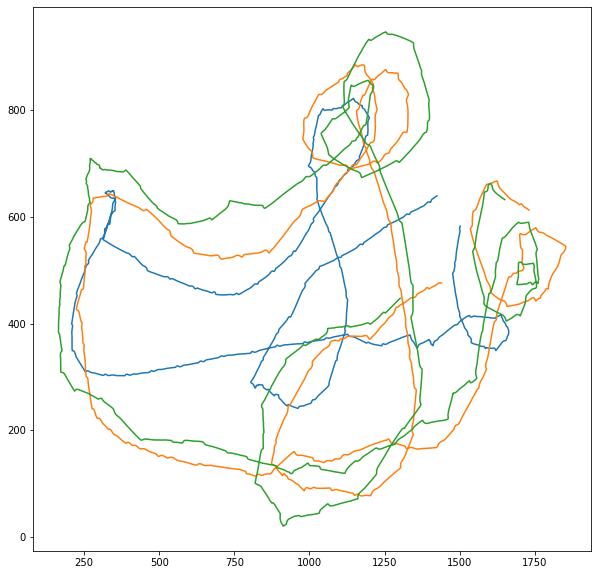

In [6]:
plt.figure(figsize=(10, 10))

def plot_trajectories(dfs, ids=[], **kwargs):
    for i in ids:
        plt.plot(dfs[i]['x'], dfs[i]['y'], **kwargs)

plot_trajectories(dfs, ids=[0,  3,  9])

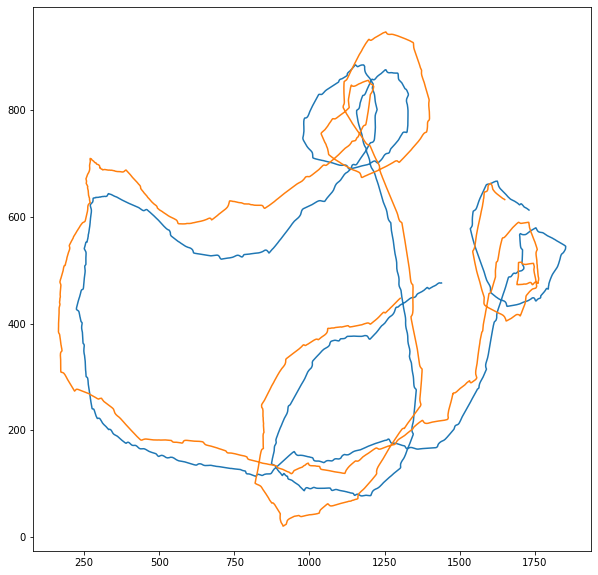

In [7]:
plt.figure(figsize=(10, 10))
plot_trajectories(dfs, ids=[3, 9])

In [209]:
def get_trajectories(dfs):
    trajectories = [df[['heading_x', 'heading_y']].values for df in dfs]
    return np.array(trajectories)

trajectories = get_trajectories(dfs)
trajectories[0]

array([[-0.91313581, -0.40765548],
       [-0.93344704, -0.35871523],
       [-0.93728987, -0.34855085],
       ...,
       [ 0.00679522,  0.99997691],
       [ 0.07979835,  0.99681103],
       [ 0.16483212,  0.98632164]])

In [210]:
def get_trajectories(dfs):
    trajectories = [df[['x', 'y']].values for df in dfs]
    return np.array(trajectories)

trajectories = get_trajectories(dfs)
trajectories[0]

array([[1424.12838916,  639.59099957],
       [1422.20491059,  638.90244065],
       [1420.62640165,  638.17848464],
       ...,
       [1499.95255268,  579.11240961],
       [1500.62638787,  580.84998769],
       [1501.52661081,  582.7759434 ]])

In [126]:
average_trajectory = np.mean(trajectories, axis=0)

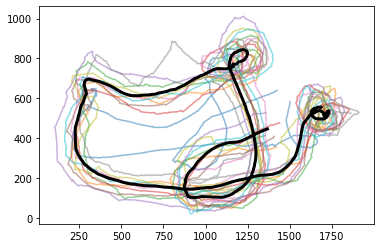

In [211]:
for t in trajectories:
    plt.plot(t[:, 0], t[:, 1], alpha=0.5)
plt.plot(average_trajectory[:, 0], average_trajectory[:, 1], color='black', linewidth=3)

In [179]:
trajectories.shape

(10, 3596, 2)

In [190]:
def get_projections(dfs):
    trajectories = get_trajectories(dfs)
    average_trajectory = np.mean(trajectories, axis=0)

    projections = []

    # Calculate the projection of each average trajectory onto the average trajectory of all objects
    for trajectory in trajectories:
        projection = []
        for i in range(1, len(trajectory)):
            # Calculate the vector from the previous point
            t = trajectory[i] - trajectory[i-1]
            tavg = average_trajectory[i] - average_trajectory[i-1]
            
            projection.append(np.dot(t, tavg) / np.linalg.norm(tavg))
        projections.append(np.abs(np.array(projection)))

    # Convert the list of projections to a np array
    projections = np.array(projections)
    return projections

In [186]:
projections = []

# Calculate the projection of each average trajectory onto the average trajectory of all objects
for trajectory in trajectories:
    projection = []
    for i in range(1, len(trajectory)):
        # Calculate the vector from the previous point
        t = trajectory[i] - trajectory[i-1]
        tavg = average_trajectory[i] - average_trajectory[i-1]
        
        projection.append(np.dot(t, tavg) / np.linalg.norm(tavg))
    projections.append(np.abs(np.array(projection)))

# Convert the list of projections to a np array
projections = np.array(projections)

In [181]:
projections[0].shape

(3595,)

In [182]:
len(projections)

10

In [169]:
avg_displacement = [np.abs(np.diff(np.sqrt(df['x']**2 + df['y']**2))) for df in dfs]

array([1.9856349 , 2.07429069, 2.11885155, ..., 1.23213778, 1.15234593,
       1.16013548])

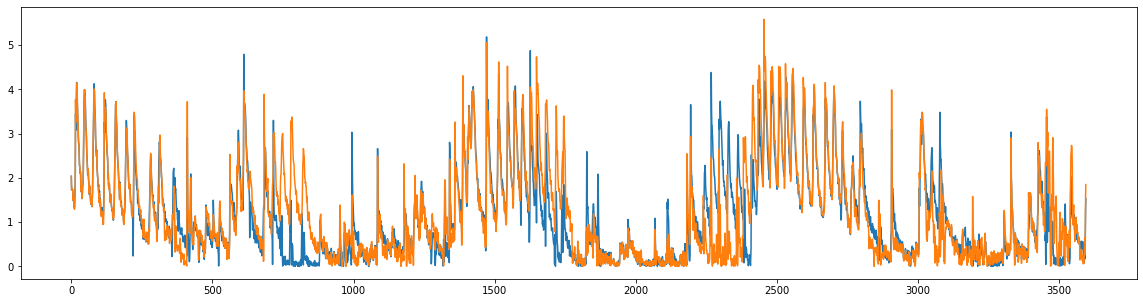

In [185]:
fig = plt.figure(figsize=(20, 5))
plt.plot(displacements[0])

plt.plot(np.abs(projections[0]))
# plt.plot(np.mean(displacements, axis=0), color='black', linewidth=3, alpha=0.5)


# Videos

In [8]:
# np.asarray(packets[0].decode()[0].to_image())

In [9]:
# Initialize an empty list to store the frames
import av
container = av.open('/home/roman/Documents/code/SmartNets_Seminars/hackathon/0066/0066_000-calib.mov')

video_frames = []

packets = list(container.demux())

for packet in packets[:900]:
    for frame in packet.decode():
        # if frame.type == 'video':
        img = frame.to_image()  # PIL/Pillow image
        arr = np.asarray(img)
        # Append the frame to the list
        video_frames.append(arr)

# Convert the list of frames into a numpy array
video_array = np.array(video_frames)
video_array.shape

(900, 1032, 1920, 3)

In [11]:
for i, frame in enumerate(video_array[::30]):
    fig = plt.figure(figsize=(20, 10))
    # plt.subplot(3, 3, i + 1)
    plt.imshow(frame)
    # plot_trajectories(dfs, ids=[3, 9], alpha=0.5)
    for k, df in enumerate(dfs):
        plt.scatter(df['x'][i*30], df['y'][i*30], s=100, alpha=0.5, label=k)
    for df in dfs:
        plt.plot(df['x'][:i*30], df['y'][:i*30], alpha=0.5)
    plt.legend()
    plt.savefig(f'/home/roman/Documents/code/SmartNets_Seminars/hackathon/0066/pics/frame_{i}.png')
    
    
    # Close the figure to free up memory
    plt.close(fig)

## Similarity

In [13]:
def similarity(df1, df2):
    return np.sqrt((df1['x'] - df2['x'])**2 + (df1['y'] - df2['y'])**2).mean()

In [14]:
similarity_matrix = np.empty((len(dfs), len(dfs)))

# Calculate the similarity for each pair of arrays
for i in range(len(dfs)):
    for j in range(len(dfs)):
        similarity_matrix[i, j] = similarity(dfs[i], dfs[j])

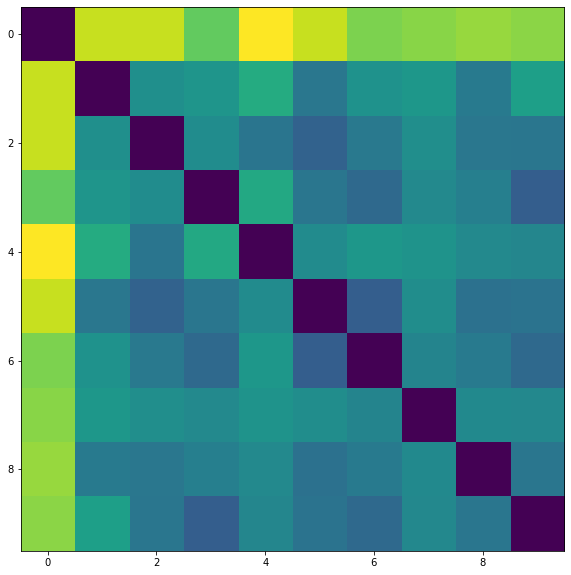

In [15]:
plt.figure(figsize=(10, 10))
plt.imshow(similarity_matrix)

# Displacements

In [12]:
displacements = [np.abs(np.diff(np.sqrt(df['x']**2 + df['y']**2))) for df in dfs]

Text(0, 0.5, 'Displacement')

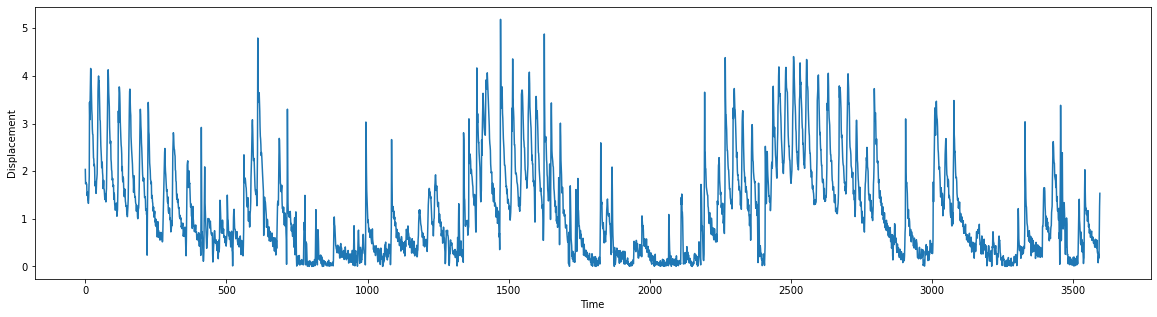

In [13]:
plt.figure(figsize=(20, 5))
plt.plot(displacements[0])
plt.xlabel('Time')
plt.ylabel('Displacement')

## Correlations

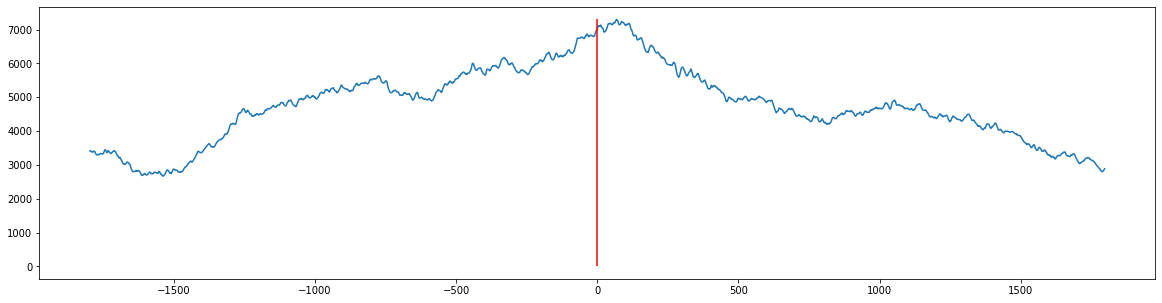

In [28]:
plt.figure(figsize=(20, 5))
x = np.linspace(-displacements[0].shape[0]/2, displacements[0].shape[0]/2, displacements[0].shape[0])
corr = signal.correlate(displacements[0], displacements[5], mode='same')
plt.plot(x, corr)
plt.vlines(0, 0, corr.max(), color='red')

In [271]:
np.argmax(corr) - displacements[0].shape[0]/2

-13.5

In [254]:
cross_correlation_matrix = np.corrcoef(displacements)
np.fill_diagonal(cross_correlation_matrix, 0)

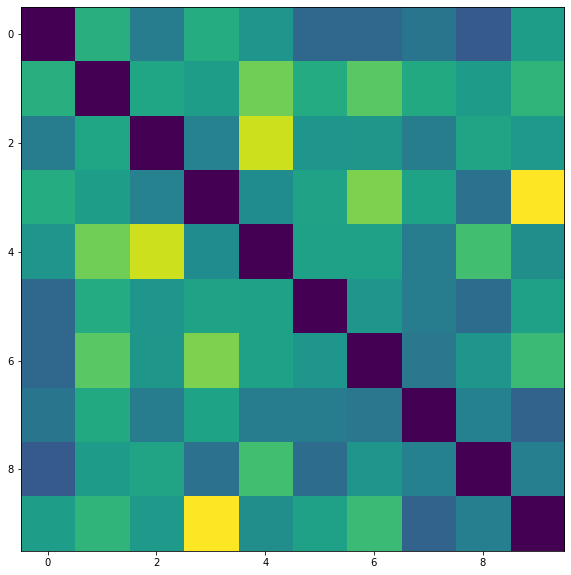

In [257]:
plt.figure(figsize=(10, 10))
plt.imshow(cross_correlation_matrix)

# Fish spikes

In [154]:
def find_peaks(displacements, threshold=1, spike_refractory_period=10, cutoff_frequency=1):
    order = 4  # Filter order

    # Design the high-pass Butterworth filter
    b, a = signal.butter(order, cutoff_frequency, btype='high', fs=30)
    filtered_signals = [signal.filtfilt(b, a, displacement) for displacement in displacements]

    peaks = [signal.find_peaks(filtered_signal, height=threshold, distance=spike_refractory_period)[0] for filtered_signal in filtered_signals]

    return peaks, filtered_signals

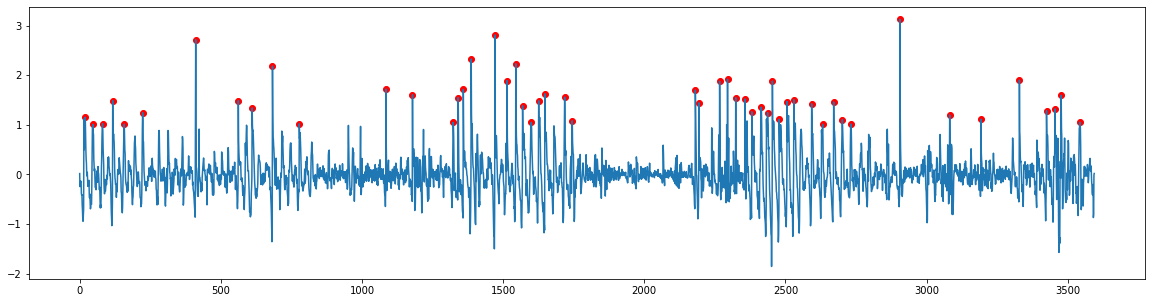

In [188]:
peaks, filtered_signals = find_peaks(projections, threshold=1, spike_refractory_period=10, cutoff_frequency=1)
plt.figure (figsize=(20, 5))
plt.plot(filtered_signals[0])
plt.scatter(peaks[0], filtered_signals[0][peaks[0]], color='red')
# plt.plot(filtered_signals[2])
# plt.scatter(peaks[2], filtered_signals[2][peaks[2]], color='blue')

In [14]:
cutoff_frequency = 1  # Cutoff frequency of the high-pass filter (in Hz)
order = 4  # Filter order

# Design the high-pass Butterworth filter
b, a = signal.butter(order, cutoff_frequency, btype='high', fs=30)

In [15]:
filtered_signals = [signal.filtfilt(b, a, displacement) for displacement in displacements]

In [16]:
peaks = [signal.find_peaks(filtered_signal, height=1, distance=10)[0] for filtered_signal in filtered_signals]

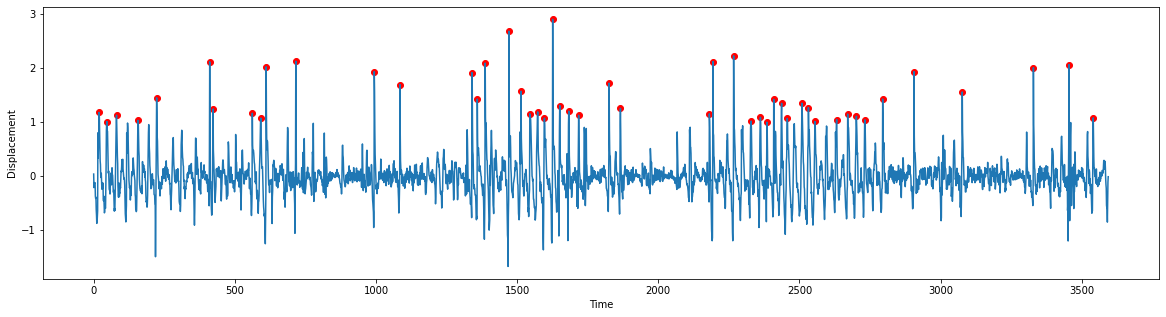

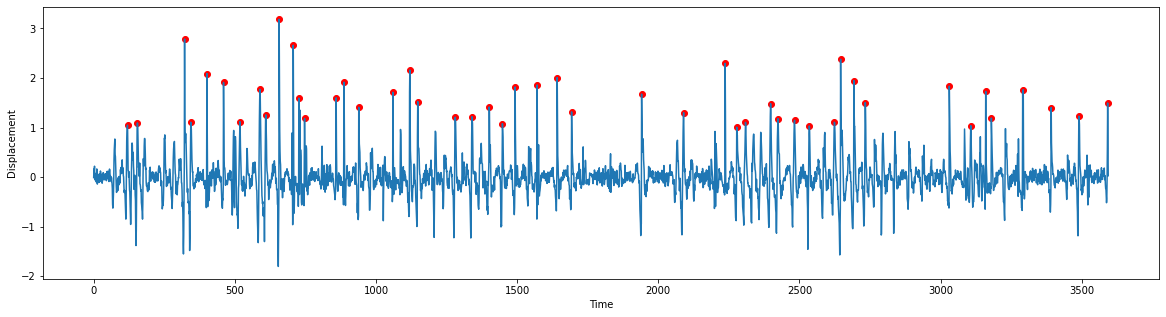

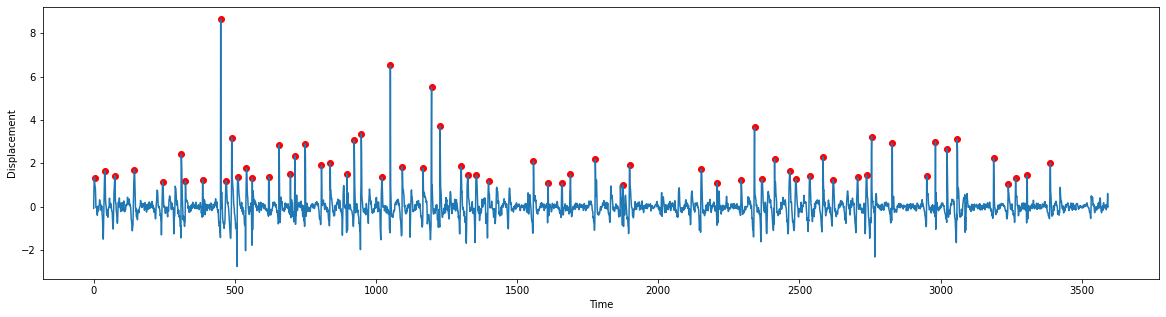

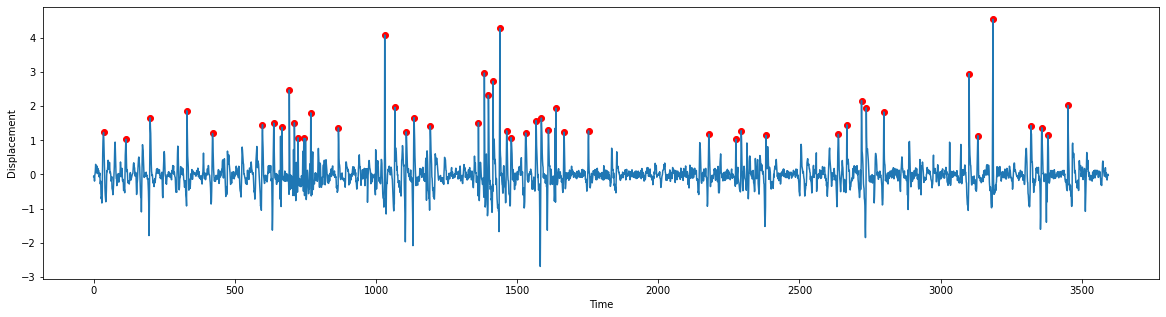

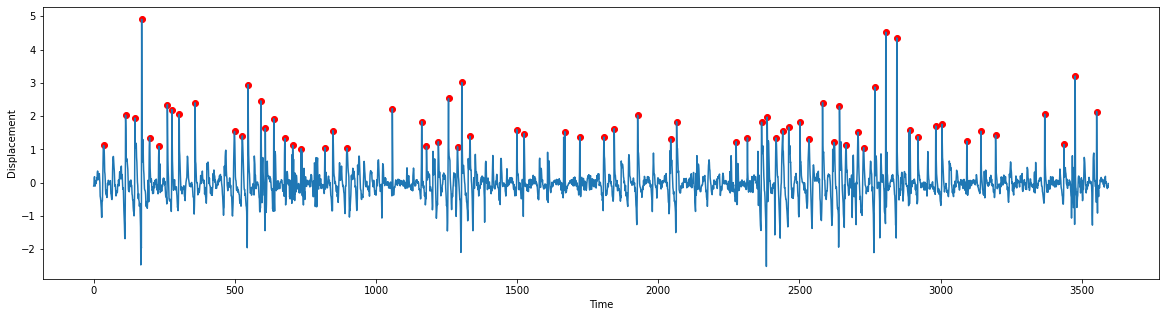

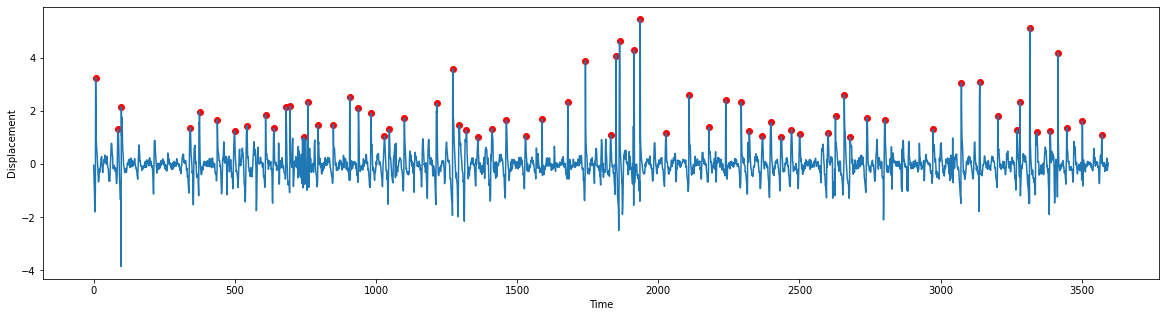

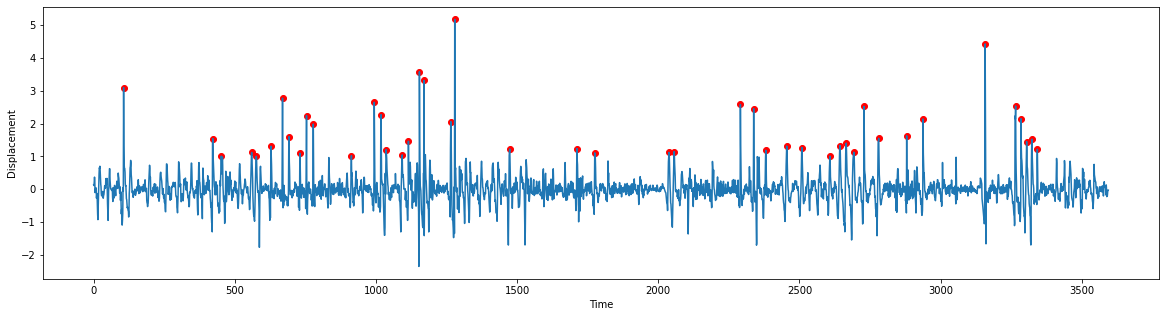

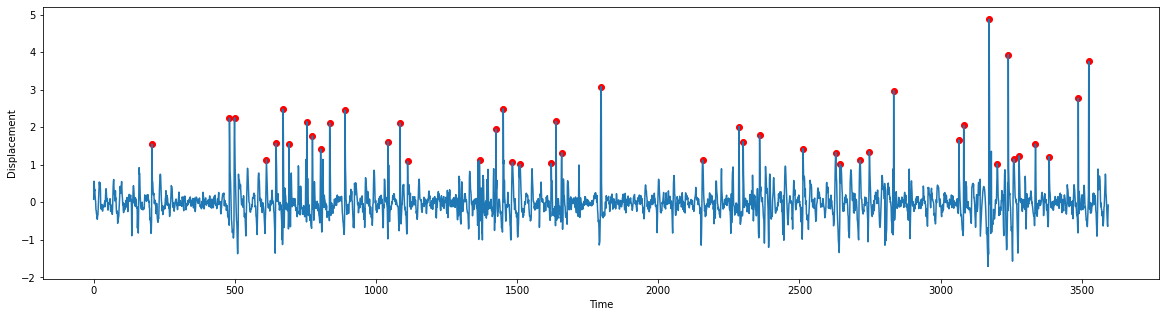

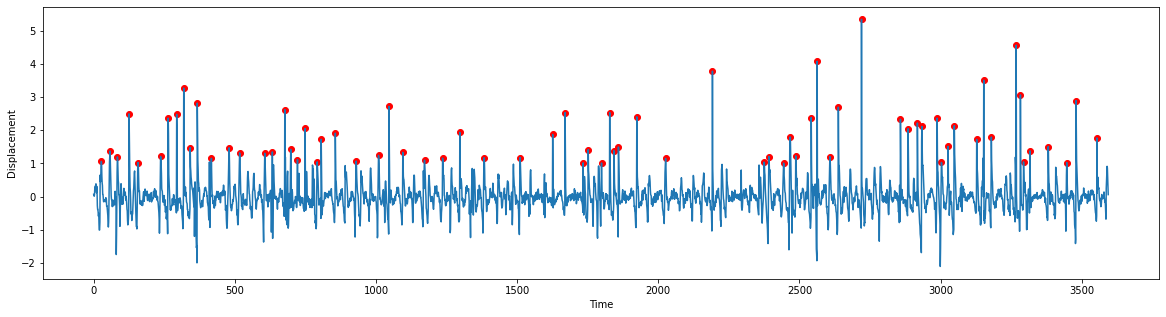

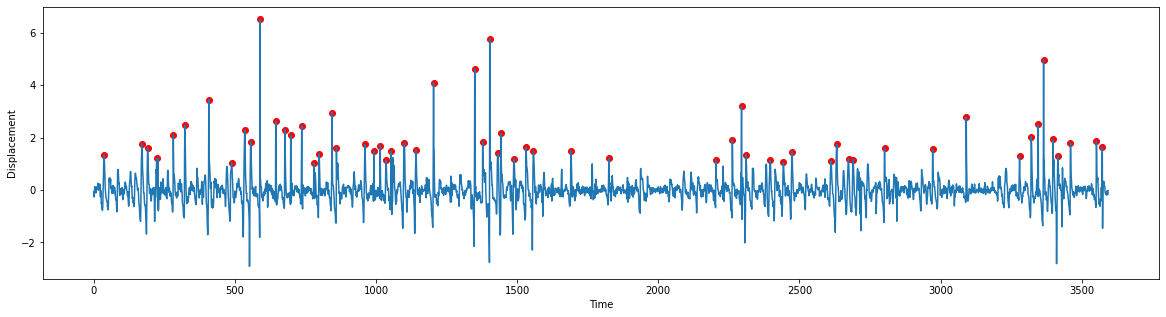

In [17]:
for filtered_signal, peak in zip(filtered_signals, peaks):
    plt.figure(figsize=(20, 5))
    plt.plot(filtered_signal)
    plt.scatter(peak, filtered_signal[peak], color='red')
    plt.xlabel('Time')
    plt.ylabel('Displacement')

## Raster plot

Text(0, 0.5, 'Fish ID')

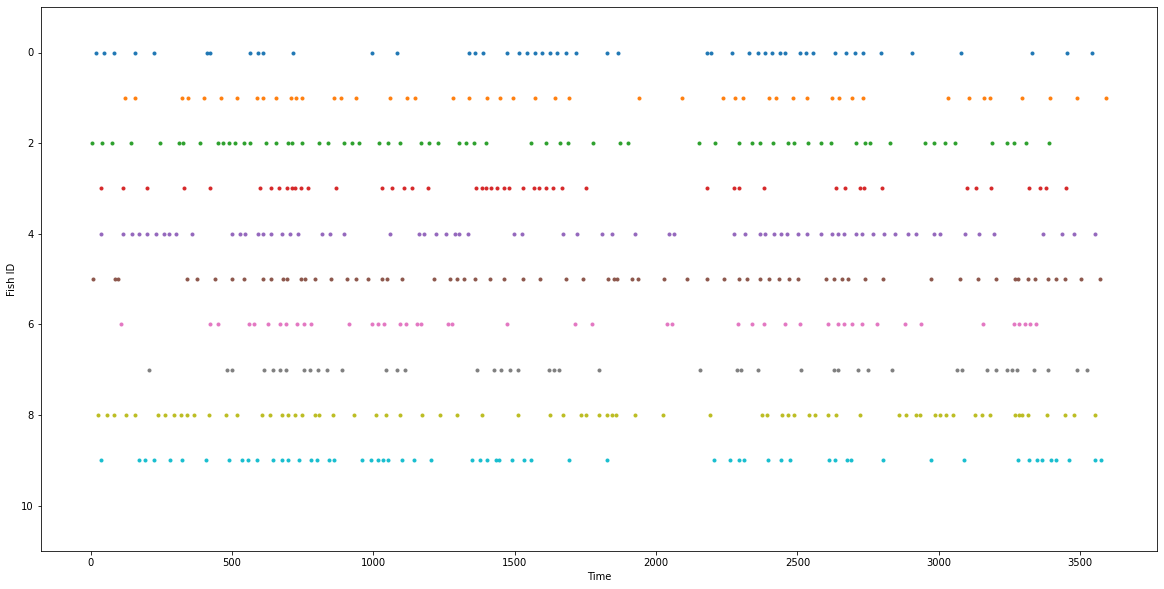

In [18]:
plt.figure(figsize=(20, 10))
for i, p in enumerate(peaks):
    plt.plot(p, i*np.ones_like(p), '.')
plt.ylim(11, -1)
plt.xlabel('Time')
plt.ylabel('Fish ID')

Text(0, 0.5, 'Fish ID')

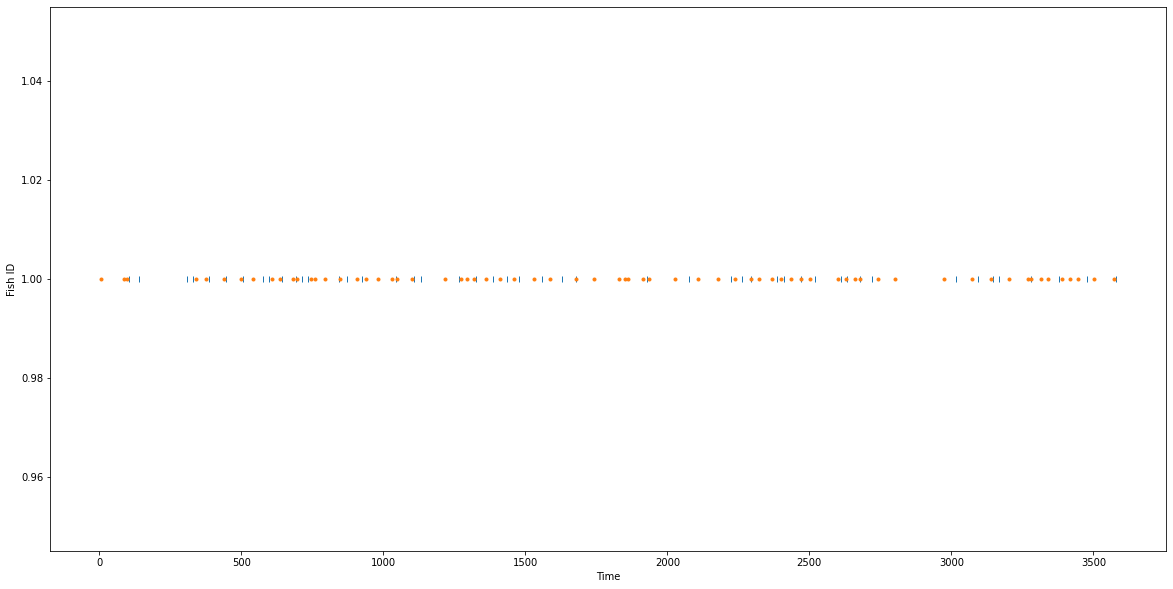

In [35]:
plt.figure(figsize=(20, 10))

plt.plot(peaks[1] - 13.5, np.ones_like(peaks[1]), '|')
plt.plot(peaks[5], np.ones_like(peaks[5]), '.')

plt.xlabel('Time')
plt.ylabel('Fish ID')

# Fish plasticity

In [36]:
def exponential_decay_kernel(tau, length):
    t = np.arange(length)
    return np.exp(-t / tau)

In [37]:
exp_decay_kernel = exponential_decay_kernel(15, 90)

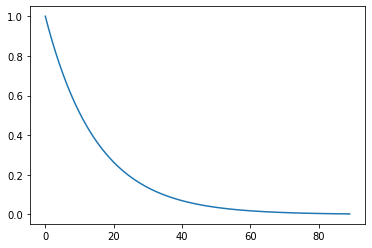

In [38]:
plt.plot(exp_decay_kernel)

In [39]:
def convolve_spike_train_with_kernel(spike_train, kernel):
    return np.convolve(spike_train, kernel, 'full')

In [40]:
spike_train = np.zeros_like(displacements[0])
spike_train[peaks[0]] = 1

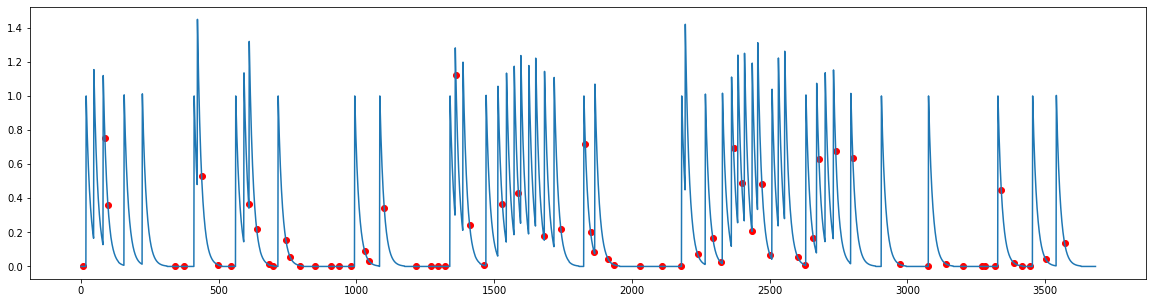

In [41]:
plt.figure(figsize=(20, 5))
conv = convolve_spike_train_with_kernel(spike_train, exp_decay_kernel)
plt.plot(conv)
plt.scatter(peaks[5], conv[peaks[5]], color='red')

In [42]:
spike_train_2 = np.zeros_like(displacements[0])
spike_train_2[peaks[5]] = 1

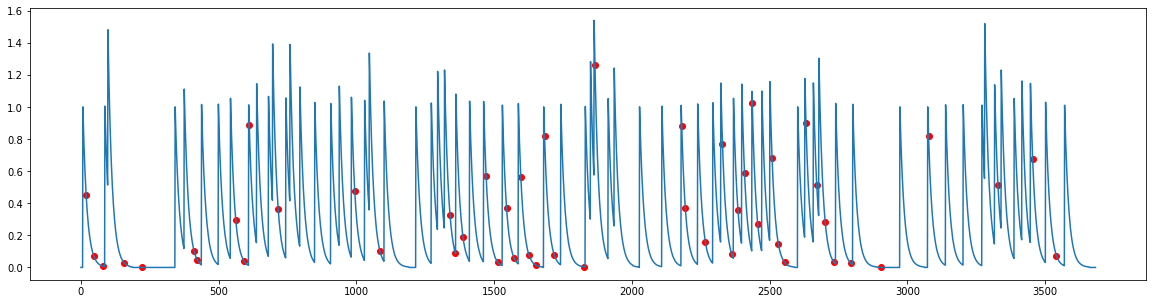

In [43]:
plt.figure(figsize=(20, 5))
conv2 = convolve_spike_train_with_kernel(spike_train_2, exp_decay_kernel)
plt.plot(conv2)
plt.scatter(peaks[0], conv2[peaks[0]], color='red')

In [44]:
exp_kerr

0.951229424500714

## Iterative approach

In [19]:
tau = 20
trace1 = [0]
trace2 = [0]
exp_kerr = np.exp(-1/tau)
w = [0]
spike_times = [-1000]
for i in range(1,len(displacements[0])):
    trace1.append(trace1[-1])
    trace2.append(trace2[-1])
    if i in peaks[9] and i - spike_times[-1] > 10:
        trace1[i]+=1
        w.append(w[-1] - trace2[i])
        spike_times.append(i)
    if i in peaks[3] and i - spike_times[-1] > 10:
        trace2[i]+=1
        w.append(w[-1] + trace1[i])
        spike_times.append(i)
    trace1[i]*=exp_kerr
    trace2[i]*=exp_kerr

len(w)

84

In [63]:
tau = 20
trace1 = [0]
trace2 = [0]
exp_kerr = np.exp(-1/tau)
w = np.zeros(len(displacements[0]))
spike_times = [-1000]
for i in range(1,len(displacements[0])):
    trace1.append(trace1[-1])
    trace2.append(trace2[-1])
    if i in peaks[9] and i - spike_times[-1] > 10:
        trace1[i]+=1
        w[i] = (w[i-1] - trace2[i])
        spike_times.append(i)
    if i in peaks[3] and i - spike_times[-1] > 10:
        trace2[i]+=1
        w[i] = (w[i-1] + trace1[i])
        spike_times.append(i)
    trace1[i]*=exp_kerr
    trace2[i]*=exp_kerr

w_orig = w.copy()
# Interpolate missing values in w
x = np.where(w != 0)[0]  # indices where w is not zero
y = w[x]  # non-zero elements of w
xi = np.arange(len(w))  # all indices
w = np.interp(xi, x, y)  # interpolate

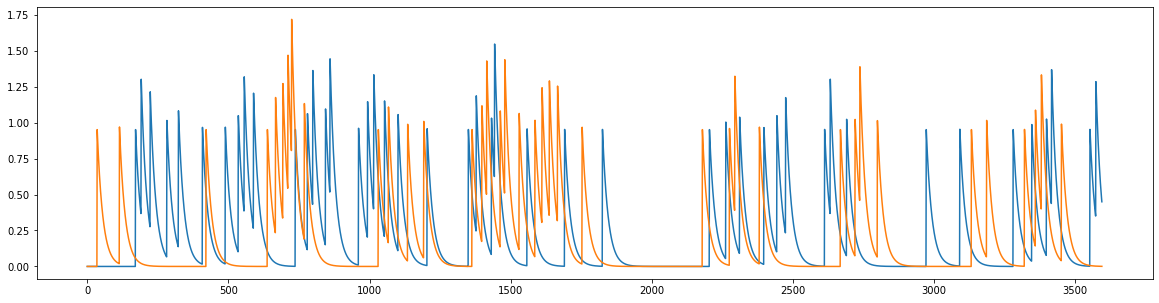

In [20]:
fig = plt.figure(figsize=(20, 5))
plt.plot(trace1)
plt.plot(trace2)

In [91]:
def calculate_leadership_score(tmax, leader_sequence, follower_sequence, tau=20, refractory_period=10):
    trace1 = [0]
    trace2 = [0]
    exp_kerr = np.exp(-1/tau)
    w = [0]
    spike_times = [-1000]
    for i in range(1, tmax):
        trace1.append(trace1[-1])
        trace2.append(trace2[-1])
        if i in follower_sequence and i - spike_times[-1] > refractory_period:
            trace1[i]+=1
            w.append(w[-1] - trace2[i])
            spike_times.append(i)
        if i in leader_sequence and i - spike_times[-1] > refractory_period:
            trace2[i]+=1
            w.append(w[-1] + trace1[i])
            spike_times.append(i)
        trace1[i]*=exp_kerr
        trace2[i]*=exp_kerr

    spike_times = spike_times[1:]
    w = w[1:]
    
    return w, spike_times, trace1, trace2

In [ ]:
tmax = len(displacements[0])

In [45]:
def stretch_leadership_score(w, spike_times, tmax):
    w_stretched = np.zeros(tmax)
    for idx, i in enumerate(spike_times):
        w_stretched[i] = w[idx]
    
    x = np.where(w_stretched != 0)[0]  # indices where w is not zero
    y = w_stretched[x]  # non-zero elements of w
    xi = np.arange(len(w_stretched))  # all indices
    w_stretched = np.interp(xi, x, y)  # interpolate

    return w_stretched

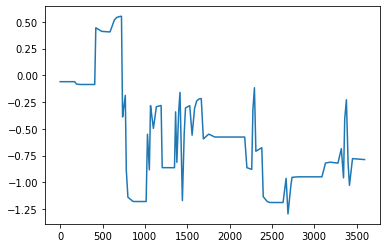

In [23]:
w_orig = w_stretched.copy()
# Interpolate missing values in w
x = np.where(w_stretched != 0)[0]  # indices where w is not zero
y = w_stretched[x]  # non-zero elements of w
xi = np.arange(len(w_stretched))  # all indices
w_stretched = np.interp(xi, x, y)  # interpolate
plt.plot(w_stretched)

In [112]:
# concat_peaks = np.array(sorted(peaks[3].tolist() + peaks[9].tolist()))

# filtered_peaks = []
# for i in range(len(concat_peaks)):
#     if i == 0 or concat_peaks[i] - concat_peaks[i-1] >= 10:
#         filtered_peaks.append(concat_peaks[i])

# filtered_peaks = np.array(filtered_peaks)
# len(filtered_peaks)
    

85

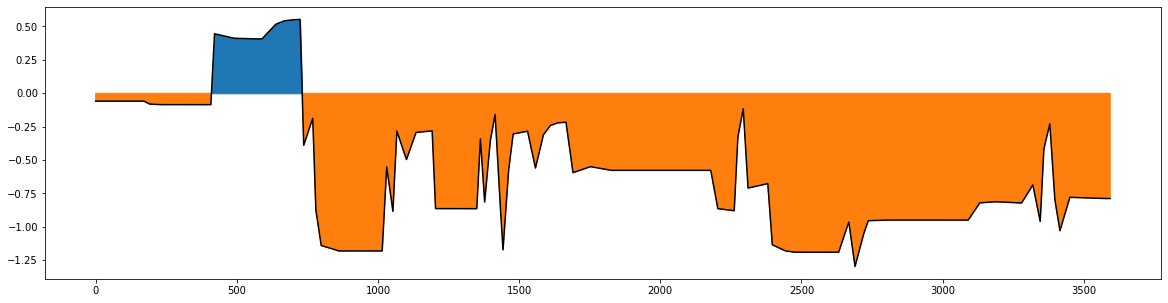

In [24]:
w = np.array(w_stretched)
fig = plt.figure(figsize=(20, 5))
plt.plot(w_stretched, color='black')
plt.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched >= 0), color='C0', interpolate=True)  # green for above zero
plt.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched <= 0), color='C1', interpolate=True)  # red for below zero

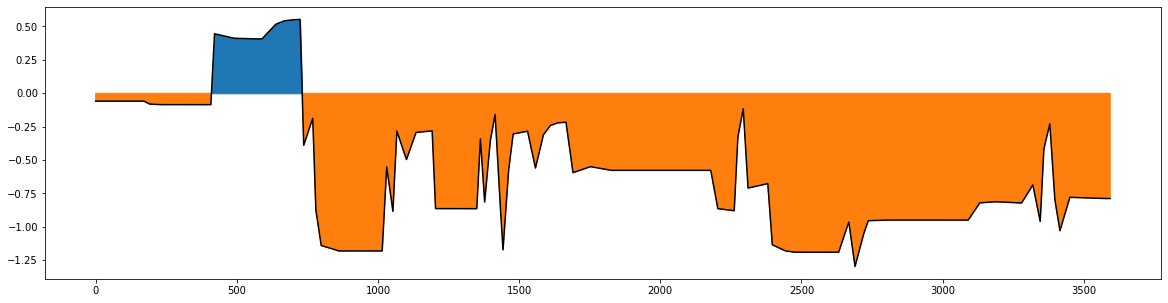

In [25]:
w = np.array(w)
fig = plt.figure(figsize=(20, 5))
plt.plot(w, color='black')
plt.fill_between(range(len(w)), w, where=(w >= 0), color='C0', interpolate=True)  # green for above zero
plt.fill_between(range(len(w)), w, where=(w <= 0), color='C1', interpolate=True)  # red for below zero

In [30]:
def draw_frame(ax, frame_number):
    ax.vlines(frame_number, -2, 2, color='black')

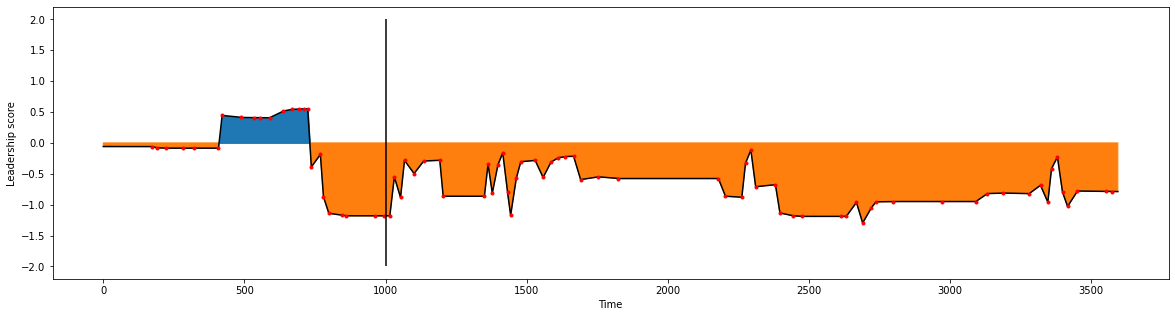

In [31]:
w_stretched = np.array(w_stretched)
fig = plt.figure(figsize=(20, 5))
plt.plot(w_stretched, color='black')
plt.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched >= 0), color='C0', interpolate=True)  # green for above zero
plt.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched <= 0), color='C1', interpolate=True)  # red for below zero
plt.plot(np.where(w_orig != 0)[0].reshape(-1), w_orig[np.where(w_orig != 0)], '.r')
plt.xlabel('Time')
plt.ylabel('Leadership score')

draw_frame(plt.gca(), 1000)

In [ ]:
for i, frame in enumerate(video_array[::30]):
    fig, axes = plt.subplots(2, 1, figsize=(20, 20))
    # plt.subplot(3, 3, i + 1)
    plt.sca(axes[0])
    plt.imshow(frame)
    # plot_trajectories(dfs, ids=[3, 9], alpha=0.5)
    for k, df in enumerate(dfs):
        plt.scatter(df['x'][i*30], df['y'][i*30], s=100, alpha=0.5, label=k)
    for df in dfs:
        plt.plot(df['x'][:i*30], df['y'][:i*30], alpha=0.5)
    plt.legend()
    plt.savefig(f'/home/roman/Documents/code/SmartNets_Seminars/hackathon/0066/pics/frame_{i}.png')
    plt.sca(axes[1])
    plt.plot(w_stretched, color='black')
    plt.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched >= 0), color='C0', interpolate=True)  # green for above zero
    plt.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched <= 0), color='C1', interpolate=True)  # red for below zero
    plt.plot(np.where(w_orig != 0)[0].reshape(-1), w_orig[np.where(w_orig != 0)], '.r')
    plt.xlabel('Time')
    plt.ylabel('Leadership score')
    draw_frame(plt.gca(), i*30)
    if i > 3: break

    
    
    # Close the figure to free up memory
    # plt.close(fig)

In [46]:
tmax = len(displacements[0])
w, spike_times, _, _ = calculate_leadership_score(tmax, leader_sequence=peaks[2], follower_sequence=peaks[3])
w_stretched = stretch_leadership_score(w, spike_times, tmax)

In [52]:
import os

In [214]:
def lidership_plot(dfs, leader_id, follower_id, video_array, threshold=1, refractory_period=10, tau=20, use_projections=False):
    
    if use_projections:
        displacements = get_projections(dfs)
    else:
        displacements = [np.abs(np.diff(np.sqrt(df['x']**2 + df['y']**2))) for df in dfs]
    tmax = len(displacements[0])
    peaks, _ = find_peaks(displacements, threshold=threshold)
    w, spike_times, _, _ = calculate_leadership_score(tmax, leader_sequence=peaks[leader_id], follower_sequence=peaks[follower_id], tau=tau, refractory_period=refractory_period)
    w_stretched = stretch_leadership_score(w, spike_times, tmax)

    if not os.path.exists(f'/home/roman/Documents/code/SmartNets_Seminars/hackathon/0066/pics_{leader_id}_{follower_id}'):
        os.mkdir(f'/home/roman/Documents/code/SmartNets_Seminars/hackathon/0066/pics_{leader_id}_{follower_id}')

    for i, frame in enumerate(video_array[::30]):
        fig = plt.figure(figsize=(20, 20))
        gs = gridspec.GridSpec(3, 1)  # 3 rows, 1 column

        ax0 = plt.subplot(gs[0:2, :])  # First two rows for the first plot
        ax0.imshow(frame)
        for k, df in enumerate(dfs):
            alpha = 0.7 if k in [leader_id, follower_id] else 0.2
            ax0.scatter(df['x'][i*30], df['y'][i*30], s=100, alpha=alpha, label=k)
        for k, df in enumerate(dfs):
            alpha = 0.7 if k in [leader_id, follower_id] else 0.2
            ax0.plot(df['x'][:i*30], df['y'][:i*30], alpha=alpha)
        ax0.legend()

        ax1 = plt.subplot(gs[2, :])  # Last row for the second plot
        ax1.plot(w_stretched, color='black')
        ax1.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched >= 0), color=f'C{leader_id}', interpolate=True)  # green for above zero
        ax1.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched <= 0), color=f'C{follower_id}', interpolate=True)  # red for below zero
        ax1.set_xlabel('Time')
        ax1.set_ylabel('Leadership score')
        draw_frame(ax1, i*30)

        
        plt.savefig(f'/home/roman/Documents/code/SmartNets_Seminars/hackathon/0066/pics_{leader_id}_{follower_id}/frame_{i}.png')

        # Close the figure to free up memory
        plt.close(fig)

In [216]:
lidership_plot(dfs, 2, 1, video_array, threshold=1, refractory_period=10)

In [ ]:
import matplotlib.gridspec as gridspec

for i, frame in enumerate(video_array[::30]):
    fig = plt.figure(figsize=(20, 20))
    gs = gridspec.GridSpec(3, 1)  # 3 rows, 1 column

    ax0 = plt.subplot(gs[0:2, :])  # First two rows for the first plot
    ax0.imshow(frame)
    for k, df in enumerate(dfs):
        alpha = 0.7 if k in [3, 9] else 0.2
        ax0.scatter(df['x'][i*30], df['y'][i*30], s=100, alpha=alpha, label=k)
    for k, df in enumerate(dfs):
        alpha = 0.7 if k in [3, 9] else 0.2
        ax0.plot(df['x'][:i*30], df['y'][:i*30], alpha=alpha)
    ax0.legend()

    ax1 = plt.subplot(gs[2, :])  # Last row for the second plot
    ax1.plot(w_stretched, color='black')
    ax1.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched >= 0), color='C0', interpolate=True)  # green for above zero
    ax1.fill_between(range(len(w_stretched)), w_stretched, where=(w_stretched <= 0), color='C1', interpolate=True)  # red for below zero
    ax1.plot(np.where(w_orig != 0)[0].reshape(-1), w_orig[np.where(w_orig != 0)], '.r')
    ax1.set_xlabel('Time')
    ax1.set_ylabel('Leadership score')
    draw_frame(ax1, i*30)

    plt.savefig(f'/home/roman/Documents/code/SmartNets_Seminars/hackathon/0066/pics/frame_{i}.png')

    # Close the figure to free up memory
    plt.close(fig)


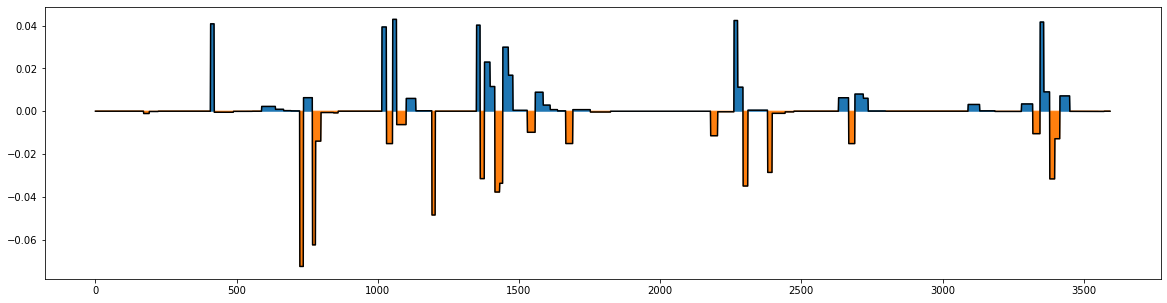

In [27]:
w = np.array(w)
fig = plt.figure(figsize=(20, 5))
plt.plot(np.diff(w), color='black')
plt.fill_between(range(len(np.diff(w))), np.diff(w), where=(np.diff(w) >= 0), color='C0', interpolate=True)  # green for above zero
plt.fill_between(range(len(np.diff(w))), np.diff(w), where=(np.diff(w) <= 0), color='C1', interpolate=True)  # red for below zero

In [397]:
np.sum(conv[peaks[5]]), np.sum(conv2[peaks[0]])

(11.600319607972976, 16.514838029992426)

# Closest spike

In [ ]:
peaks[5][:5]

array([  7,  87,  98, 342, 375])

In [ ]:
peaks[4][:5]

array([ 35, 113, 146, 170, 198])

(0.0, 3.0)

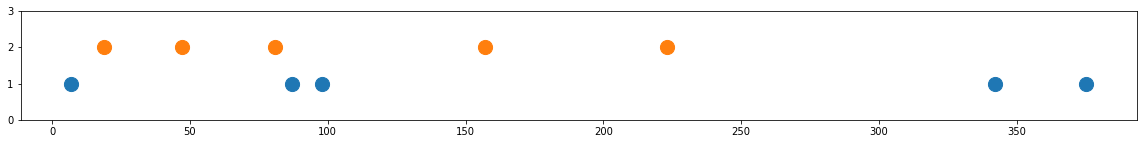

In [ ]:
plt.figure(figsize=(20, 2))
plt.scatter(peaks[5][:5], np.ones_like(peaks[5][:5]), s=200)
plt.scatter(peaks[0][:5], 2*np.ones_like(peaks[0][:5]), s=200)
plt.ylim(0, 3)

In [ ]:
calculate_time_difference(peaks[5][:5], peaks[4][:5])

array([-28, -26, -15, 144, 177])

In [349]:
calculate_time_difference(peaks[4][:5], peaks[5][:5])

array([ 28,  15,  48,  72, 100])

In [339]:
np.array([[p - p2 for p in peaks[5]][np.argmin(np.abs([p - p2 for p in peaks[5]]))] for p2 in peaks[4]]).mean()

1.75

In [347]:
import numpy as np

def find_closest_spike(spike, sequence):
    time_differences = [spike - s for s in sequence]
    return time_differences[np.argmin(np.abs(time_differences))]

def calculate_time_difference(sequence1, sequence2):
    time_difference = np.array([find_closest_spike(s, sequence2) for s in sequence1])
    return time_difference


In [326]:
closest_spikes_matrix = []
for p1 in peaks:
    closest_spikes = []
    for p2 in peaks:
        closest_spikes.append(calculate_mean_time_difference(p1, p2))
    closest_spikes_matrix.append(closest_spikes)

In [334]:
calculate_mean_time_difference(peaks[5], peaks[1])

-8.279411764705882

In [329]:
np.array(closest_spikes_matrix).shape

(10, 10)

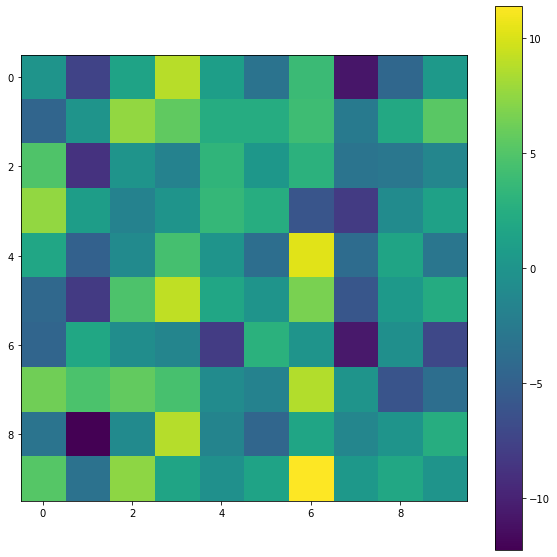

In [332]:
plt.figure(figsize=(10, 10))
plt.imshow(np.array(closest_spikes_matrix))
plt.colorbar()

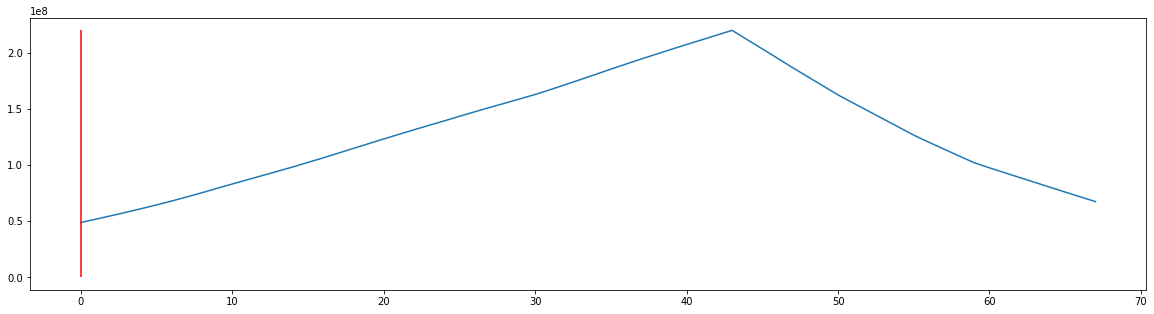

In [290]:
plt.figure(figsize=(20, 5))
x = np.linspace(-peaks[0].shape[0]/2, peaks[0].shape[0]/2, peaks[0].shape[0])
corr = signal.correlate(peaks[5], peaks[3], mode='same')
plt.plot(corr)
plt.vlines(0, 0, corr.max(), color='red')


In [276]:
np.corrcoef(peaks[1] - 13.5, peaks[5][:peaks[1].shape[0]])

array([[1.        , 0.99365738],
       [0.99365738, 1.        ]])

# ISI

In [226]:
interspike_intervals = [np.diff(peak) for peak in peaks]

Text(0, 0.5, 'Interspike interval')

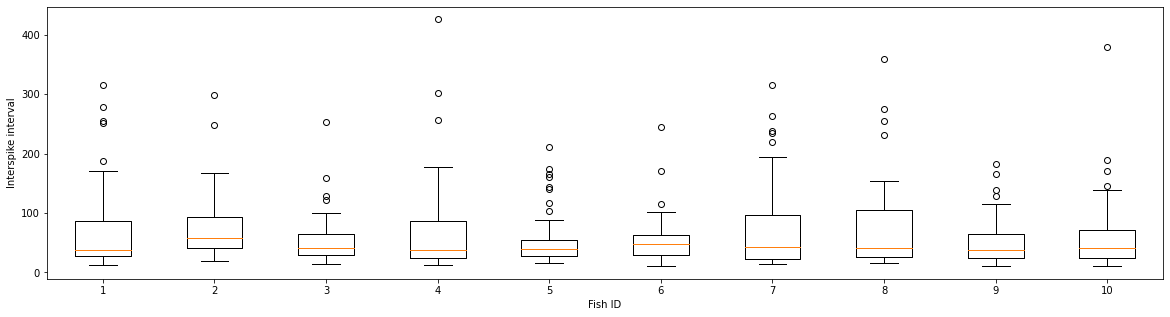

In [229]:
#boxplot
plt.figure(figsize=(20, 5))
plt.boxplot(interspike_intervals);
plt.xlabel('Fish ID')
plt.ylabel('Interspike interval')

In [140]:
velocities = [np.abs(np.diff(np.sqrt(df['x']**2 + df['y']**2))).mean() for df in dfs]
velocities

[1.1476513607761267,
 1.2672502886715171,
 1.4022842312360357,
 1.4477088609757336,
 1.3705319077062454,
 1.5518765215445403,
 1.441243775730991,
 1.2908297080156257,
 1.3652191738338613,
 1.4564419675772546]

In [142]:
[l/v for l, v in zip(body_lengths, velocities)]

[46.11137278034807,
 55.875044379564926,
 61.194372388804126,
 55.834200139829825,
 45.247965828879835,
 49.402163662143145,
 59.380437876108225,
 64.33835550223358,
 49.47141936983312,
 53.451059301385364]